# Метрики и кривые обучения

Поддерживает две модели: **SASRec** и **Flow Matching**.  
Чтобы переключиться — измени `MODEL_TYPE` в следующей ячейке.

In [10]:
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm

sys.path.append('../src')
from data import build_dataloaders
from evaluate import evaluate

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

In [11]:
# ════════════════════════════════════════════════════════════════════
# КОНФИГ — измени MODEL_TYPE и CKPT_DIR
# ════════════════════════════════════════════════════════════════════

MODEL_TYPE = 'fm'                               # 'sasrec'  или  'fm'
CKPT_DIR   = Path('../checkpoints/baseline_2') # путь к чекпойнту

# Параметры FM, которые нельзя вывести из весов:
FM_NUM_STEPS = 50
FM_W_CFG     = 1.0

# ─────────────────────────────────────────────────────────────────────
DATA_DIR    = Path('../data/ATG')
PADDING_IDX = 11924
BATCH_SIZE  = 256

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device:     {device}')
print(f'Model type: {MODEL_TYPE.upper()}')

ckpt_path = CKPT_DIR / 'best.pt'
if not ckpt_path.exists():
    ckpt_path = CKPT_DIR / 'latest.pt'
print(f'Checkpoint: {ckpt_path}  (exists={ckpt_path.exists()})')

Device:     cuda
Model type: FM
Checkpoint: ..\checkpoints\baseline_2\best.pt  (exists=True)


In [12]:
from models.sasrec import SASRec
from models.flow_matcher import FlowMatcher

ckpt = torch.load(ckpt_path, map_location=device)
print(f'Checkpoint: epoch={ckpt.get("epoch")}, metrics={ckpt.get("metrics")}')
sd = ckpt['model_state']

if MODEL_TYPE == 'sasrec':
    d_model     = sd['item_embedding.weight'].shape[1]
    n_items     = sd['item_embedding.weight'].shape[0] - 1
    max_seq_len = sd['pos_embedding.weight'].shape[0]
    n_layers    = sum(1 for k in sd if k.startswith('blocks.') and k.endswith('.norm1.weight'))
    d_ff        = sd['blocks.0.ff.0.weight'].shape[0]
    tie_weights = 'output_proj.weight' not in sd
    print(f'Inferred: d_model={d_model}, n_items={n_items}, max_seq_len={max_seq_len}, '
          f'n_layers={n_layers}, d_ff={d_ff}, tie_weights={tie_weights}')

    model = SASRec(
        n_items=n_items, padding_idx=n_items,
        d_model=d_model, n_layers=n_layers, d_ff=d_ff,
        max_seq_len=max_seq_len, tie_weights=tie_weights,
        n_heads=4, dropout=0.0,
    ).to(device)

else:  # fm
    n_components = sd['whitening_V'].shape[1]
    d_hidden     = sd['encoder.input_proj.weight'].shape[0]
    d_cond       = sd['encoder.output_proj.weight'].shape[0]
    enc_layers   = sum(1 for k in sd if k.startswith('encoder.transformer.layers.') and k.endswith('.norm1.weight'))
    den_blocks   = sum(1 for k in sd if k.startswith('denoiser.blocks.') and k.endswith('.norm.weight'))
    den_d_block  = sd['denoiser.blocks.0.norm.weight'].shape[0]
    den_d_ff     = sd['denoiser.blocks.0.ff.0.weight'].shape[0]
    print(f'Inferred: n_components={n_components}, d_hidden={d_hidden}, d_cond={d_cond}, '
          f'enc_layers={enc_layers}, den_blocks={den_blocks}, den_d_block={den_d_block}')

    with open(DATA_DIR / '3large_emb.pickle', 'rb') as f:
        emb_raw = pickle.load(f).astype(np.float32)

    model = FlowMatcher(
        item_embeddings_raw=emb_raw,
        padding_idx=PADDING_IDX,
        n_components=n_components,
        whitening_cache_path=Path('../data/processed/whitening_cache.npz'),
        d_hidden=d_hidden, d_cond=d_cond,
        encoder_layers=enc_layers, encoder_heads=8, encoder_d_ff=2048,
        denoiser_d_block=den_d_block, denoiser_d_ff=den_d_ff,
        denoiser_n_blocks=den_blocks, denoiser_time_emb_dim=128,
    ).to(device)

model.load_state_dict(sd)

ema_shadow = ckpt.get('ema_shadow', {})
if ema_shadow:
    for name, param in model.named_parameters():
        if name in ema_shadow:
            param.data.copy_(ema_shadow[name].to(device))
    print('EMA weights loaded')

model.eval()
summary = model.param_summary()
print(f'Trainable params: {summary["total_trainable"]:,}')
print('Model ready')

Checkpoint: epoch=95, metrics={'HR@10': 0.015971148386597633, 'NDCG@10': 0.014430739916861057, 'HR@20': 0.01803194172680378, 'NDCG@20': 0.014937503263354301}
Inferred: n_components=256, d_hidden=512, d_cond=512, enc_layers=2, den_blocks=6, den_d_block=512
Loading whitening from cache: ..\data\processed\whitening_cache.npz
EMA weights loaded
Trainable params: 16,492,800
Model ready


In [13]:
# Загружаем все три сплита
loaders = build_dataloaders(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    num_workers=0,
    splits=('train', 'val', 'test'),
)
print(f'Train: {len(loaders["train"].dataset):,}')
print(f'Val:   {len(loaders["val"].dataset):,}')
print(f'Test:  {len(loaders["test"].dataset):,}')

Train: 15,529
Val:   1,941
Test:  1,942


## 1. Loss по сплитам

In [14]:
def compute_split_loss(model, loader, device, seed=42, use_amp=True):
    """Считает средний loss на одном сплите (работает для FM и SASRec)."""
    amp_dtype  = torch.bfloat16
    total_loss = 0.0
    n_batches  = 0

    torch.manual_seed(seed)
    with torch.no_grad():
        for batch in tqdm(loader, desc='Computing loss', leave=False):
            history = batch['history'].to(device)
            mask    = batch['mask'].to(device)
            target  = batch['target'].to(device)

            with torch.autocast(device_type=device.type, dtype=amp_dtype,
                                enabled=(use_amp and device.type == 'cuda')):
                result = model.compute_loss(history, target, mask)
                loss = result[0] if isinstance(result, tuple) else result

            total_loss += loss.item()
            n_batches  += 1

    return total_loss / n_batches

print('Computing losses...')
train_loss = compute_split_loss(model, loaders['train'], device)
val_loss   = compute_split_loss(model, loaders['val'],   device)
test_loss  = compute_split_loss(model, loaders['test'],  device)

print(f'{"Split":<8} {"Loss":>8}')
print('-' * 20)
print(f'{"Train":<8} {train_loss:>8.4f}')
print(f'{"Val":<8} {val_loss:>8.4f}')
print(f'{"Test":<8} {test_loss:>8.4f}')
print(f'\nTrain/Val loss ratio: {train_loss / val_loss:.3f}  (1.0 = no overfit)')

Computing losses...


Computing loss:   0%|          | 0/60 [00:00<?, ?it/s]

Computing loss:   0%|          | 0/8 [00:00<?, ?it/s]

Computing loss:   0%|          | 0/8 [00:00<?, ?it/s]

Split        Loss
--------------------
Train      0.7439
Val        1.8231
Test       1.8112

Train/Val loss ratio: 0.408  (1.0 = no overfit)


## 2. HR@K и NDCG@K по сплитам

In [15]:
TOP_K        = (10, 20)
num_steps    = FM_NUM_STEPS if MODEL_TYPE == 'fm' else 1
w_cfg        = FM_W_CFG     if MODEL_TYPE == 'fm' else 0.0

print('Evaluating train...')
torch.manual_seed(42)
train_metrics = evaluate(
    model=model, dataloader=loaders['train'],
    top_k_values=TOP_K, num_sample_steps=num_steps,
    w_cfg=w_cfg, device=device, show_progress=True,
)

print('Evaluating val...')
torch.manual_seed(42)
val_metrics = evaluate(
    model=model, dataloader=loaders['val'],
    top_k_values=TOP_K, num_sample_steps=num_steps,
    w_cfg=w_cfg, device=device, show_progress=True,
)

print('Evaluating test...')
torch.manual_seed(42)
test_metrics = evaluate(
    model=model, dataloader=loaders['test'],
    top_k_values=TOP_K, num_sample_steps=num_steps,
    w_cfg=w_cfg, device=device, show_progress=True,
)

rows = []
for split, m in [('Train', train_metrics), ('Val', val_metrics), ('Test', test_metrics)]:
    rows.append({'Split': split, **{k: f'{v:.4f}' for k, v in m.items()}})

df = pd.DataFrame(rows).set_index('Split')
print('\n', df.to_string())

Evaluating train...


Evaluating val...


Evaluating test...



         HR@10 NDCG@10   HR@20 NDCG@20
Split                                
Train  0.9224  0.9112  0.9266  0.9123
Val    0.0160  0.0144  0.0180  0.0149
Test   0.0154  0.0141  0.0165  0.0144


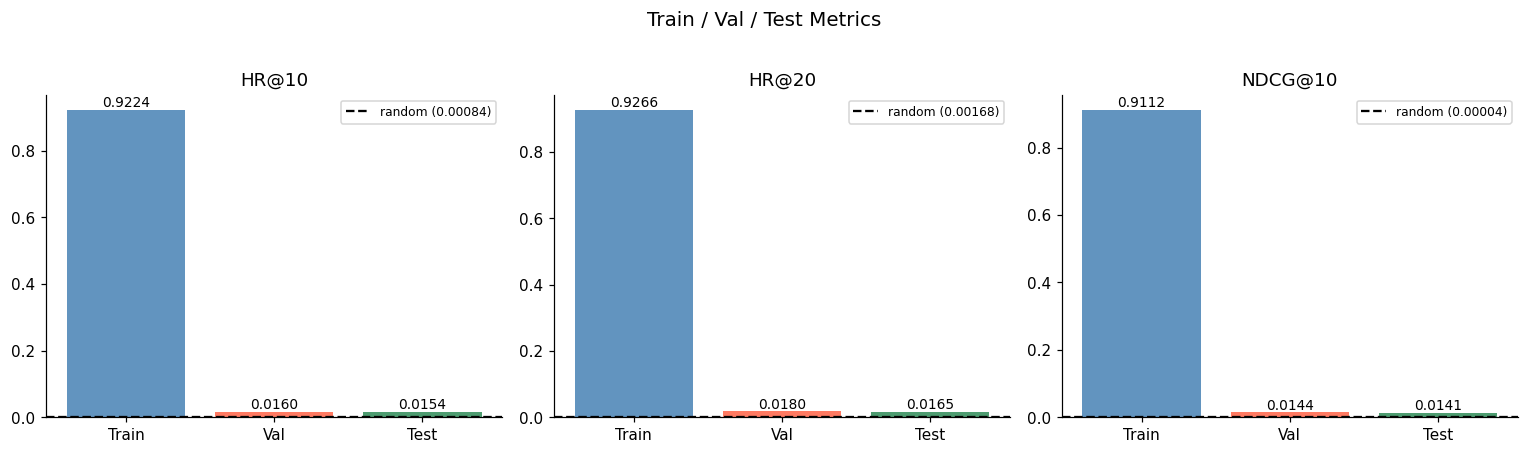

In [16]:
# Визуализация
splits   = ['Train', 'Val', 'Test']
hr10     = [train_metrics['HR@10'],   val_metrics['HR@10'],   test_metrics['HR@10']]
hr20     = [train_metrics['HR@20'],   val_metrics['HR@20'],   test_metrics['HR@20']]
ndcg10   = [train_metrics['NDCG@10'], val_metrics['NDCG@10'], test_metrics['NDCG@10']]

# Случайный baseline для ATG: K / N_items
N_ITEMS = 11924
random_hr10  = 10  / N_ITEMS
random_hr20  = 20  / N_ITEMS
random_ndcg10 = sum(1/np.log2(r+2) for r in range(10)) / 10 / N_ITEMS  # approx

x = np.arange(len(splits))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, vals, baseline, title in [
    (axes[0], hr10,   random_hr10,  'HR@10'),
    (axes[1], hr20,   random_hr20,  'HR@20'),
    (axes[2], ndcg10, random_ndcg10,'NDCG@10'),
]:
    bars = ax.bar(splits, vals, color=['steelblue', 'tomato', 'seagreen'], alpha=0.85)
    ax.axhline(baseline, color='black', ls='--', lw=1.5,
               label=f'random ({baseline:.5f})')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + baseline*0.1,
                f'{v:.4f}', ha='center', va='bottom', fontsize=9)
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.suptitle('Train / Val / Test Metrics', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 3. Кривые обучения из log.csv

Train rows: 107, Val rows: 21
Train cols: ['epoch', 'step', 'loss', 'lr', 'elapsed_s']
Val cols:   ['epoch', 'step', 'val_loss', 'train_ndcg20', 'HR@10', 'NDCG@10', 'HR@20', 'NDCG@20']


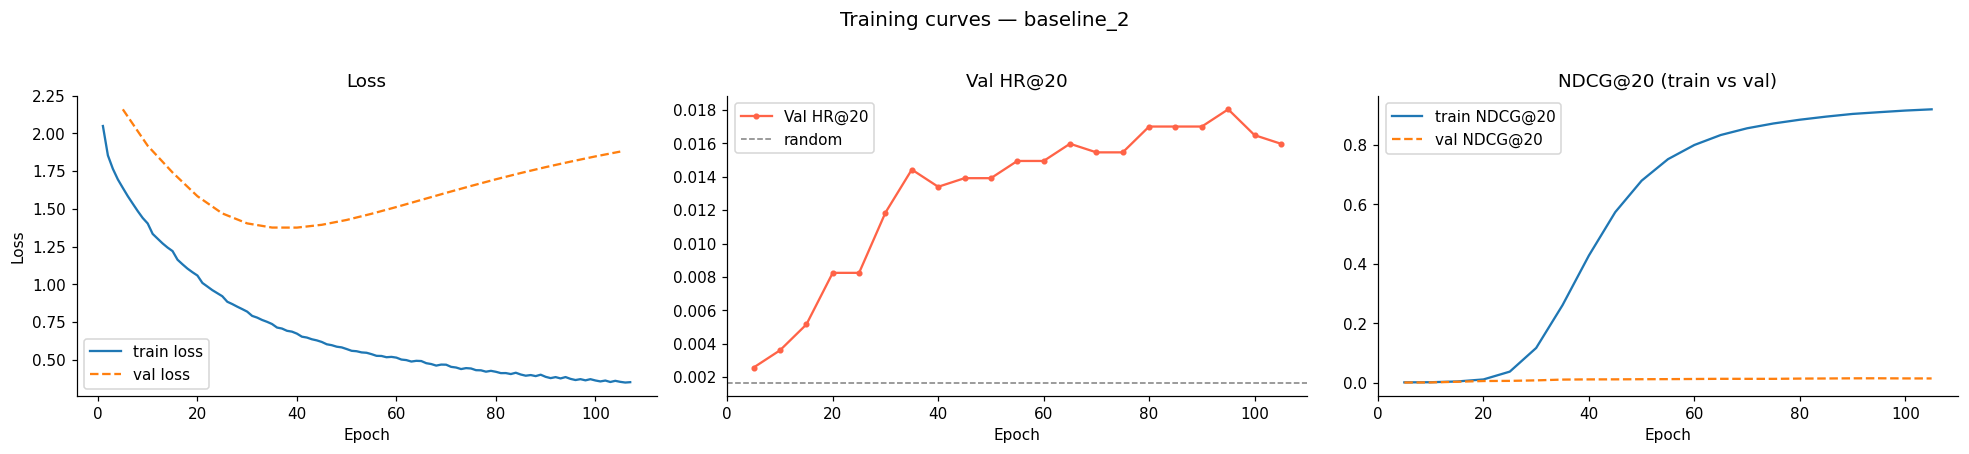

In [17]:
log_train_path = CKPT_DIR / 'log_train.csv'
log_val_path   = CKPT_DIR / 'log_val.csv'

if not log_train_path.exists() and not log_val_path.exists():
    print(f'Logs not found in {CKPT_DIR}')
else:
    train_log = pd.read_csv(log_train_path) if log_train_path.exists() else pd.DataFrame()
    val_log   = pd.read_csv(log_val_path)   if log_val_path.exists()   else pd.DataFrame()

    # убираем строки с нечисловым epoch (например "test")
    if len(val_log):
        val_log = val_log[pd.to_numeric(val_log['epoch'], errors='coerce').notna()].copy()
        val_log['epoch'] = val_log['epoch'].astype(int)

    print(f'Train rows: {len(train_log)}, Val rows: {len(val_log)}')
    print(f'Train cols: {list(train_log.columns)}')
    print(f'Val cols:   {list(val_log.columns)}')

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    ax = axes[0]
    if len(train_log) and 'loss' in train_log.columns:
        ax.plot(train_log['epoch'], train_log['loss'], lw=1.5, label='train loss')
    if len(val_log) and 'val_loss' in val_log.columns:
        ax.plot(val_log['epoch'], val_log['val_loss'], lw=1.5, label='val loss', ls='--')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.set_title('Loss'); ax.legend()

    ax = axes[1]
    if len(val_log) and 'HR@20' in val_log.columns:
        ax.plot(val_log['epoch'], val_log['HR@20'], 'o-', lw=1.5, ms=3, color='tomato', label='Val HR@20')
        ax.axhline(20 / 11924, color='gray', ls='--', lw=1, label='random')
    ax.set_xlabel('Epoch'); ax.set_title('Val HR@20'); ax.legend()

    ax = axes[2]
    if len(val_log) and 'train_ndcg20' in val_log.columns:
        ax.plot(val_log['epoch'], val_log['train_ndcg20'], lw=1.5, label='train NDCG@20')
    if len(val_log) and 'NDCG@20' in val_log.columns:
        ax.plot(val_log['epoch'], val_log['NDCG@20'], lw=1.5, ls='--', label='val NDCG@20')
    ax.set_xlabel('Epoch'); ax.set_title('NDCG@20 (train vs val)'); ax.legend()

    plt.suptitle(f'Training curves — {CKPT_DIR.name}', fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

## 4. Сравнение моделей

Запусти ноутбук дважды — один раз с `MODEL_TYPE = 'sasrec'`, второй с `MODEL_TYPE = 'fm'` — и вставь метрики сюда.

        Val HR@10  Val NDCG@10  Val HR@20  Val NDCG@20  Test HR@10  Test NDCG@10  Test HR@20  Test NDCG@20
SASREC     0.0526       0.0351     0.0649       0.0381      0.0433        0.0266      0.0566        0.0300
FM         0.0160       0.0144     0.0180       0.0149      0.0154        0.0141      0.0165        0.0144
Random     0.0008       0.0000     0.0017       0.0000      0.0008        0.0000      0.0017        0.0000


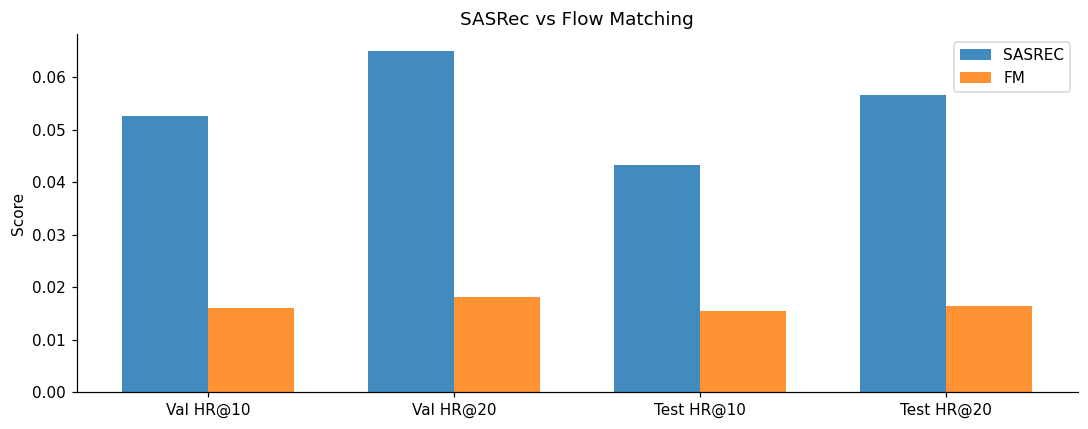

In [18]:
# Вставь метрики вручную после прогона каждой модели,
# или запусти обе модели в одном сеансе подряд и сохрани результаты.
#
# Пример заполнения:
# results = {
#     'SASRec': {'HR@10': 0.0066, 'NDCG@10': 0.0038, 'HR@20': 0.0110, 'NDCG@20': 0.0049},
#     'FM':     {'HR@10': 0.0088, 'NDCG@10': 0.0055, 'HR@20': 0.0139, 'NDCG@20': 0.0068},
# }

# Автоматическое сохранение текущей модели в словарь
if 'results' not in dir():
    results = {}

results[MODEL_TYPE.upper()] = {
    'Val HR@10':   val_metrics['HR@10'],
    'Val NDCG@10': val_metrics['NDCG@10'],
    'Val HR@20':   val_metrics['HR@20'],
    'Val NDCG@20': val_metrics['NDCG@20'],
    'Test HR@10':  test_metrics['HR@10'],
    'Test NDCG@10':test_metrics['NDCG@10'],
    'Test HR@20':  test_metrics['HR@20'],
    'Test NDCG@20':test_metrics['NDCG@20'],
}

if len(results) > 1:
    N_ITEMS = PADDING_IDX
    random_row = {
        'Val HR@10':    10 / N_ITEMS, 'Val NDCG@10':  0.0,
        'Val HR@20':    20 / N_ITEMS, 'Val NDCG@20':  0.0,
        'Test HR@10':   10 / N_ITEMS, 'Test NDCG@10': 0.0,
        'Test HR@20':   20 / N_ITEMS, 'Test NDCG@20': 0.0,
    }
    cmp = pd.DataFrame({**results, 'Random': random_row}).T
    cmp = cmp[['Val HR@10', 'Val NDCG@10', 'Val HR@20', 'Val NDCG@20',
               'Test HR@10', 'Test NDCG@10', 'Test HR@20', 'Test NDCG@20']]
    print(cmp.to_string(float_format=lambda x: f'{x:.4f}'))

    # Визуализация
    metrics_to_plot = ['Val HR@10', 'Val HR@20', 'Test HR@10', 'Test HR@20']
    models = [k for k in results]
    x = np.arange(len(metrics_to_plot))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 4))
    for i, name in enumerate(models):
        vals = [results[name][m] for m in metrics_to_plot]
        ax.bar(x + i * width, vals, width, label=name, alpha=0.85)
    ax.set_xticks(x + width / 2)
    ax.set_xticklabels(metrics_to_plot)
    ax.set_ylabel('Score')
    ax.set_title('SASRec vs Flow Matching')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f'Сохранено: {list(results.keys())}')
    print('Запусти ноутбук со второй моделью, чтобы появилась сравнительная таблица.')